In [14]:
from langgraph.graph import StateGraph, START ,END
from typing import TypedDict
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
import os


load_dotenv(override=True)  # Load environment variables from .env file

True

In [15]:
# define state
class SimpleLLM(TypedDict):
   question: str
   answer: str

In [ ]:
import os

api_key = os.getenv("OPENROUTER_API_KEY")

llm = ChatOpenAI(
    model="openrouter/free",
    base_url="https://openrouter.ai" + "/api/v1",
    api_key=api_key,
    temperature=0,
    max_tokens=300,
    max_retries=3,
)

# response = llm.invoke("How many r's are in the word 'strawberry'?")
# print(response.content)


In [17]:
def ask_question_node(state: SimpleLLM) -> SimpleLLM:
    question = state["question"]
    prompt = f"Answer the following question: {question}"
    #ask that question to llm
    answer = llm.invoke(prompt).content
    state["answer"] = answer
    return state

In [18]:
graph = StateGraph(SimpleLLM)


graph.add_node("ask_question_node", ask_question_node)

graph.add_edge(START, "ask_question_node")
graph.add_edge("ask_question_node", END)

workflow = graph.compile()


In [19]:

output = workflow.invoke({"question": "What is the capital of France?"})

print("Output of the workflow execution  Answer:", output["answer"])

Output of the workflow execution  Answer: 

The capital of France is Paris.


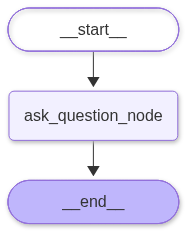

In [20]:
from IPython.display import display, Markdown , Image
# display(Markdown("### Output of the workflow execution  Bmi: {}".format(output["bmi"])))

Image(workflow.get_graph().draw_mermaid_png())
